In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv('datasets/Mall_Customers.csv')

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [7]:
from sklearn.preprocessing import OrdinalEncoder
o = OrdinalEncoder()
df['Gender'] = o.fit_transform(df[['Gender']]).ravel()

In [8]:
x = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].copy()

x = x.dropna()

In [9]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

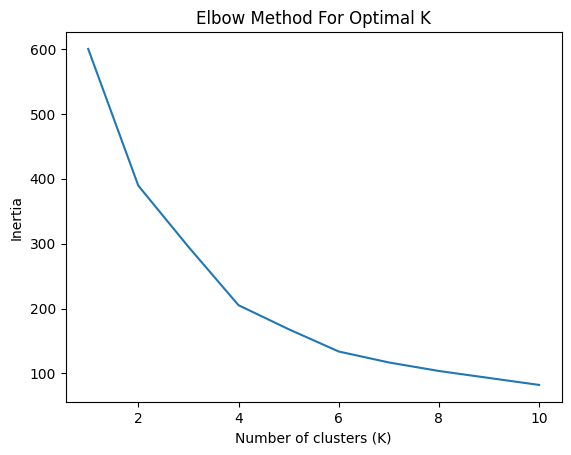

In [10]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(x_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(K_range, inertia)
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal K')
plt.show()

In [11]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df.loc[x.index, 'Cluster'] = kmeans.fit_predict(x_scaled)

In [12]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,1.0,19,15,39,0.0
1,2,1.0,21,15,81,0.0
2,3,0.0,20,16,6,0.0
3,4,0.0,23,16,77,0.0
4,5,0.0,31,17,40,0.0


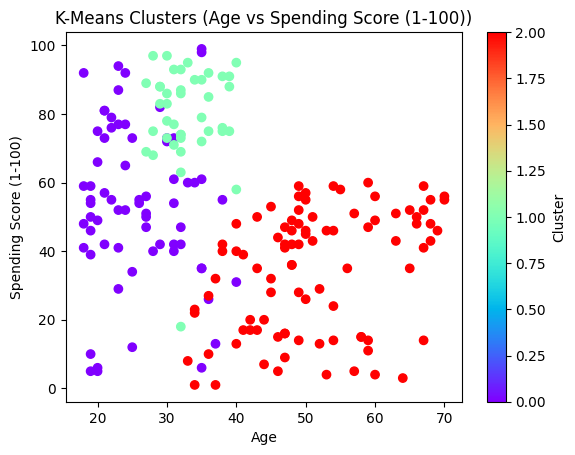

In [13]:
plt.scatter(df['Age'], df['Spending Score (1-100)'], c=df['Cluster'], cmap='rainbow')
plt.xlabel('Age')
plt.ylabel('Spending Score (1-100)')
plt.title('K-Means Clusters (Age vs Spending Score (1-100))')
plt.colorbar(label='Cluster')
plt.show()

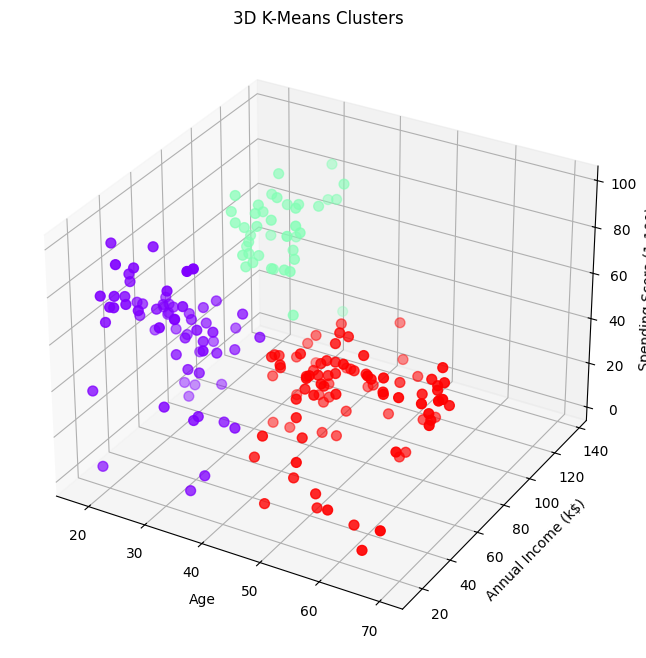

In [14]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    df['Age'],
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='rainbow',
    s=50
)

ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spending Score (1-100)')

plt.title('3D K-Means Clusters')
plt.show()

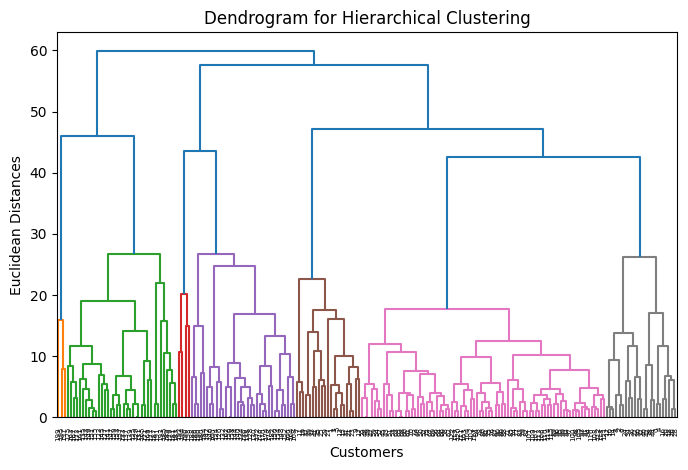

In [15]:
# hierarchical clustering
import scipy.cluster.hierarchy as clus

# hc_features = x_scaled 
hc_features = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()
hc_features = hc_features.dropna()

plt.figure(figsize=(8, 5))
linked = clus.linkage(hc_features, method="average")

den = clus.dendrogram(linked)
plt.title('Dendrogram for Hierarchical Clustering')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distances')
plt.show()


In [16]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(n_clusters=6, linkage='average')
y_means = model.fit_predict(hc_features)
y_means


array([0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3,
       0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2,
       1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 5, 2, 5, 4, 5, 4,
       5, 4])

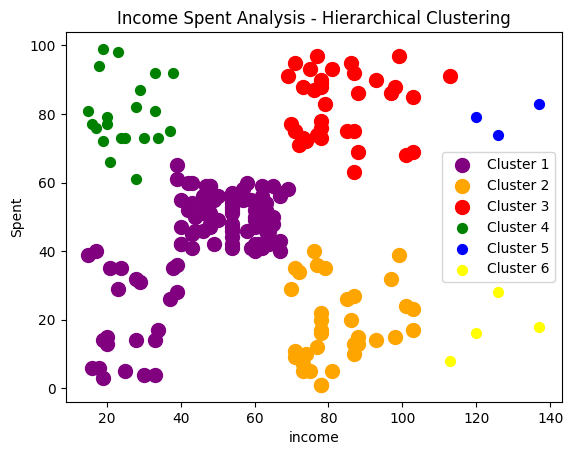

In [17]:
X = df.iloc[:, [3, 4]].values
plt.scatter(X[y_means == 0, 0], X[y_means == 0, 1], s=100, c='purple', label='Cluster 1')
plt.scatter(X[y_means == 1, 0], X[y_means == 1, 1], s=100, c='orange', label='Cluster 2')
plt.scatter(X[y_means == 2, 0], X[y_means == 2, 1], s=100, c='red', label='Cluster 3')
plt.scatter(X[y_means == 3, 0], X[y_means == 3, 1], s=50, c='green', label='Cluster 4')
plt.scatter(X[y_means == 4, 0], X[y_means == 4, 1], s=50, c='blue', label='Cluster 5')
plt.scatter(X[y_means == 5, 0], X[y_means == 5, 1], s=50, c='yellow', label='Cluster 6')

plt.title('Income Spent Analysis - Hierarchical Clustering')
plt.xlabel('income')
plt.ylabel('Spent')
plt.legend()
plt.show()


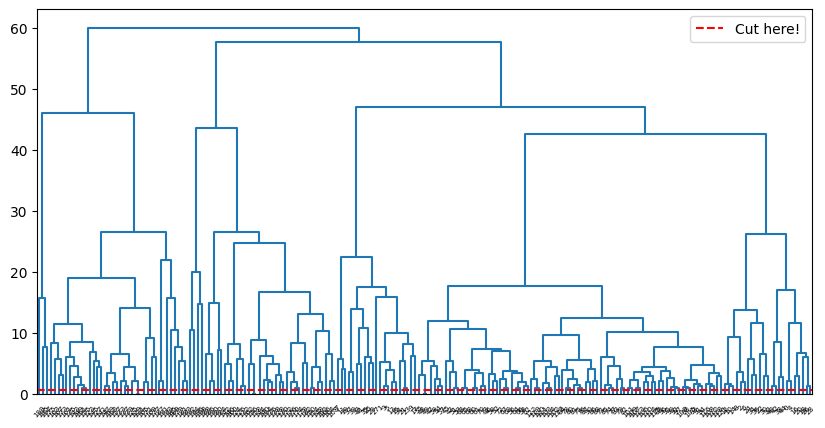

In [18]:
students = hc_features.index.astype(str).tolist()

plt.figure(figsize=(10, 5))

clus.dendrogram(
    linked,
    labels=students,
    leaf_rotation=45,
    color_threshold=0.8
)

plt.axhline(
    y=0.8,
    color="red",
    linestyle="--",
    label="Cut here!"
)

plt.legend()
plt.show()